In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import r2_score, mean_absolute_error, mean_squared_error

df = pd.read_csv('restaurant_sales_data.csv')
print(df.head())

       date  restaurant_id restaurant_type       menu_item_name meal_type  \
0  1/1/2024             11      Food Stall                Laksa     Lunch   
1  1/1/2024              7   Casual Dining  Spaghetti Carbonara    Dinner   
2  1/1/2024             23     Fine Dining         Beef Rendang    Dinner   
3  1/1/2024             22      Food Stall           Roti Canai    Dinner   
4  1/1/2024             32     Fine Dining  Spaghetti Carbonara     Lunch   

                                key_ingredients_tags  typical_ingredient_cost  \
0  rice noodles, fish broth, tamarind, shrimp pas...                      4.5   
1  spaghetti, eggs, cheese, beef bacon, black pepper                      9.0   
2  beef, coconut milk, galangal, lemongrass, spic...                      9.0   
3                     flour, ghee, egg, water, curry                      0.8   
4  spaghetti, eggs, cheese, beef bacon, black pepper                      9.0   

   observed_market_price  actual_selling_price  qu

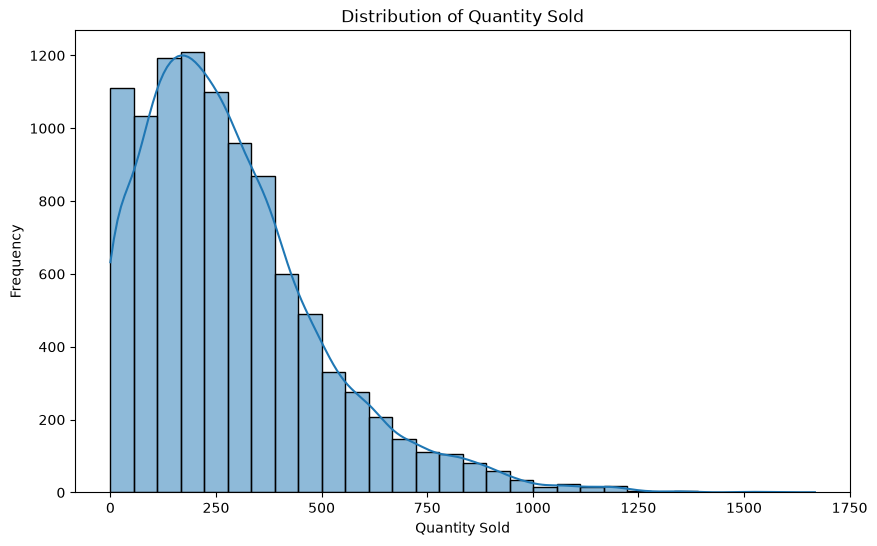

Mean Quantity Sold: 286.00
Max Quantity Sold: 1668
Min Quantity Sold: 0


In [2]:
# Distribution of Target Variable
plt.figure(figsize=(10, 6))
sns.histplot(df['quantity_sold'], bins=30, kde=True)
plt.title('Distribution of Quantity Sold')
plt.xlabel('Quantity Sold')
plt.ylabel('Frequency')
plt.show()

print(f"Mean Quantity Sold: {df['quantity_sold'].mean():.2f}")
print(f"Max Quantity Sold: {df['quantity_sold'].max()}")
print(f"Min Quantity Sold: {df['quantity_sold'].min()}")

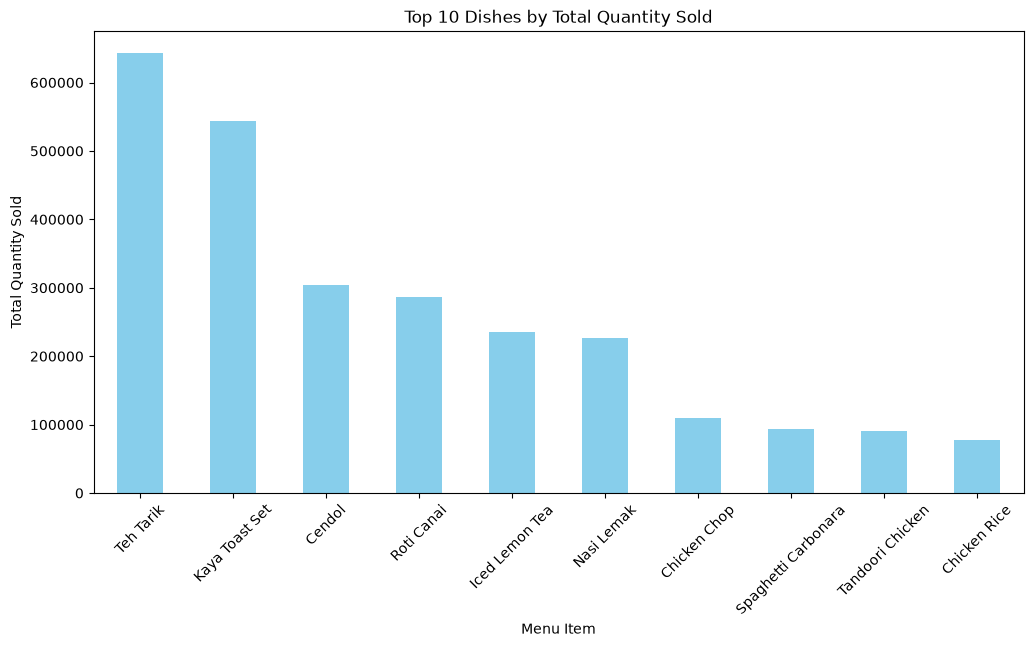

In [5]:
# Top 10 Dishes by Total Quantity Sold
plt.figure(figsize=(12, 6))
top_dishes = df.groupby('menu_item_name')['quantity_sold'].sum().sort_values(ascending=False).head(10)
top_dishes.plot(kind='bar', color='skyblue')
plt.title('Top 10 Dishes by Total Quantity Sold')
plt.xlabel('Menu Item')
plt.ylabel('Total Quantity Sold')
plt.xticks(rotation=45)
plt.show()

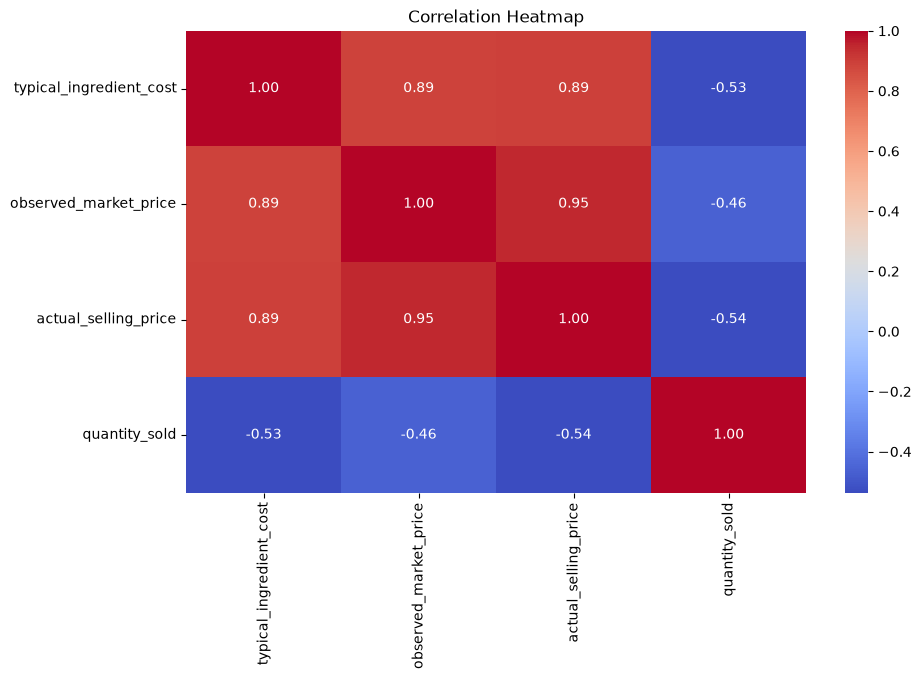

In [6]:
# Correlation Heatmap (Numerical Features only)
plt.figure(figsize=(10, 6))
numeric_cols = ['typical_ingredient_cost', 'observed_market_price', 'actual_selling_price', 'quantity_sold']
sns.heatmap(df[numeric_cols].corr(), annot=True, cmap='coolwarm', fmt='.2f')
plt.title('Correlation Heatmap')
plt.show()

In [7]:
# Feature Engineering
df['date'] = pd.to_datetime(df['date'])
df['day_of_week'] = df['date'].dt.dayofweek
df['month'] = df['date'].dt.month
df['day'] = df['date'].dt.day
df['is_weekend'] = (df['day_of_week'] >= 5).astype(int)

# Drop unnecessary text column
df = df.drop(['key_ingredients_tags'], axis=1)

# One-Hot Encode Categorical Variables
categorical_cols = ['restaurant_type', 'menu_item_name', 'meal_type',
                    'weather_condition', 'has_promotion', 'special_event']
df = pd.get_dummies(df, columns=categorical_cols, drop_first=True)

# Define X and y
X = df.drop(['quantity_sold', 'date'], axis=1)
y = df['quantity_sold']

print(f"X shape: {X.shape}")
print(f"y shape: {y.shape}")

X shape: (10000, 31)
y shape: (10000,)


In [9]:
# Split Data (80:20)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# Train Random Forest
model = RandomForestRegressor(n_estimators=200, random_state=42)
model.fit(X_train, y_train)

# Predict
y_pred = model.predict(X_test)

# Evaluate
r2 = r2_score(y_test, y_pred)
mae = mean_absolute_error(y_test, y_pred)
# ✅ FIXED: Use root_mean_squared_error for the new scikit-learn version
from sklearn.metrics import root_mean_squared_error
rmse = root_mean_squared_error(y_test, y_pred)

print(f"R² Score: {r2:.3f}")
print(f"MAE: {mae:.2f}")
print(f"RMSE: {rmse:.2f}")

R² Score: 0.812
MAE: 70.72
RMSE: 93.10


In [10]:
# Hyperparameter Tuning using Grid Search
from sklearn.model_selection import GridSearchCV

param_grid = {
    'n_estimators': [100, 200],
    'max_depth': [10, 15, None],
    'min_samples_split': [2, 5]
}

grid = GridSearchCV(RandomForestRegressor(random_state=42), param_grid, cv=3)
grid.fit(X_train, y_train)

print(f"Best Parameters: {grid.best_params_}")
print(f"Best R² Score: {grid.best_score_:.3f}")

Best Parameters: {'max_depth': 15, 'min_samples_split': 5, 'n_estimators': 200}
Best R² Score: 0.794


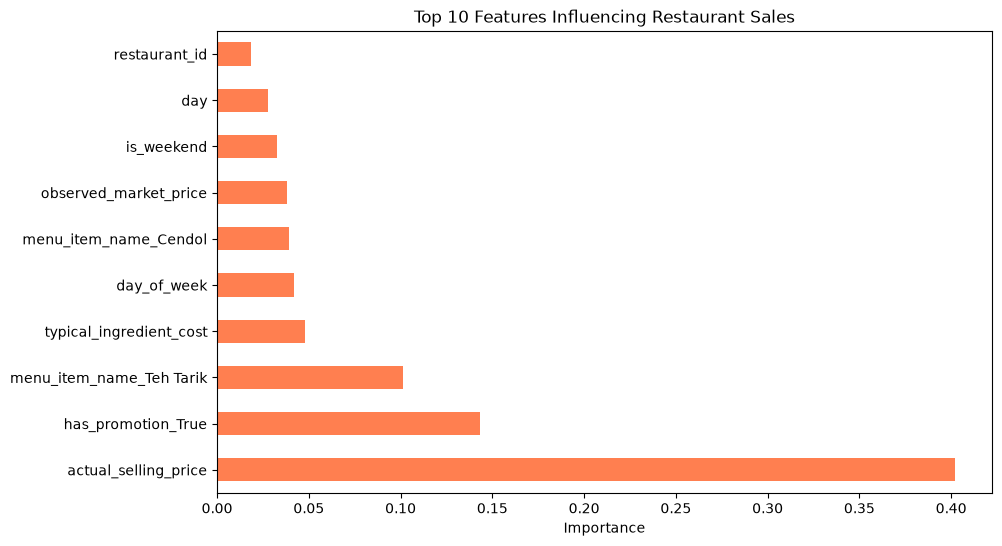


Top 5 Features:
actual_selling_price        0.402175
has_promotion_True          0.143238
menu_item_name_Teh Tarik    0.101215
typical_ingredient_cost     0.047810
day_of_week                 0.041759
dtype: float64


In [11]:
# Feature Importance from the best tuned model
best_model = grid.best_estimator_
feature_importance = pd.Series(best_model.feature_importances_, index=X.columns)
feature_importance.sort_values(ascending=False).head(10).plot(kind='barh', figsize=(10, 6), color='coral')
plt.title('Top 10 Features Influencing Restaurant Sales')
plt.xlabel('Importance')
plt.show()

print("\nTop 5 Features:")
print(feature_importance.sort_values(ascending=False).head(5))

In [12]:
# Save the best model and feature columns for the Flask app
import joblib

joblib.dump(best_model, 'model.pkl')
joblib.dump(list(X.columns), 'feature_cols.pkl')

print("✅ Model saved as model.pkl for Flask application!")

✅ Model saved as model.pkl for Flask application!


In [13]:
# Create a test input based on the user's inputs
test_input = pd.DataFrame(0, index=[0], columns=X.columns)

# Example: A Laksa at a Food Stall, Lunch, Sunny day, price 12.50
test_input['restaurant_type_Food Stall'] = 1
test_input['menu_item_name_Laksa'] = 1
test_input['meal_type_Lunch'] = 1
test_input['weather_condition_Sunny'] = 1
test_input['actual_selling_price'] = 12.50
test_input['observed_market_price'] = 10.59
test_input['typical_ingredient_cost'] = 4.5
test_input['day_of_week'] = 0  # Monday
test_input['month'] = 1
test_input['day'] = 1
test_input['is_weekend'] = 0

# Predict
predicted_qty = best_model.predict(test_input)[0]
print(f"📈 Predicted Quantity for Laksa (Lunch, Sunny): {round(predicted_qty, 2)} units")

📈 Predicted Quantity for Laksa (Lunch, Sunny): 358.02 units


In [14]:
print(df['quantity_sold'].sum())

2860004
